# Дробная диффузия по времени — Орлов

$$D_t^\alpha u=u_{xx},\quad x\in[0,1],\quad t\in[0,1],\quad u(0,t)=u(1,t)=0.$$

Производная Капуто, $0.2\leq\alpha\leq0.9$. Сетка: 128 узлов, включая края, и 500 шагов по времени. Неявная L1-схема и центральные разности по пространству.

Ноутбук использует код из `src/` и готовый локальный датасет. Генерация датасета: `python -m src.generate_dataset`.

In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'src' / 'solver.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.solver import solve_l1
from src.reference import exact_sine_solution
from src.validate import run_validation

## Проверка по Миттаг-Леффлеру

Для $u_0(x)=\sin(\pi x)$ точное решение:
$$u(x,t)=E_{\alpha,1}(-\pi^2t^\alpha)\sin(\pi x).$$

Показываем ошибки как при $T=1$, так и на всём временном интервале. Вблизи нуля решение имеет слабую временную особенность. Относительная $L_2$-ошибка считается по пространственной сетке при $T=1$.

In [2]:
metrics = run_validation(ROOT / 'results')
header = '| α | Абсолютная ошибка при T=1 | Относительная L2 при T=1 | Максимальная ошибка по времени |\n|---|---|---|---|'
rows = [f"| {m['alpha']} | {m['final_linf']:.4e} | {m['final_relative_l2']:.4%} | {m['max_linf_over_time']:.4e} |" for m in metrics]
display(Markdown(header + '\n' + '\n'.join(rows)))

Validation:
{'alpha': 0.2, 'n_x': 128, 'n_steps': 500, 'final_linf': 1.8729118927279798e-05, 'final_relative_l2': 0.00023244380133515124, 'max_linf_over_time': 0.03858317002909467, 'time_of_max_error': 0.002}
{'alpha': 0.35, 'n_x': 128, 'n_steps': 500, 'final_linf': 2.66216900731836e-05, 'final_relative_l2': 0.0003819163644949715, 'max_linf_over_time': 0.07800454317179512, 'time_of_max_error': 0.002}
{'alpha': 0.5, 'n_x': 128, 'n_steps': 500, 'final_linf': 3.12244255747246e-05, 'final_relative_l2': 0.0005490396149475286, 'max_linf_over_time': 0.07180291783599457, 'time_of_max_error': 0.002}
{'alpha': 0.75, 'n_x': 128, 'n_steps': 500, 'final_linf': 2.933324532601242e-05, 'final_relative_l2': 0.0009435091854640717, 'max_linf_over_time': 0.017376388795058983, 'time_of_max_error': 0.004}
{'alpha': 0.9, 'n_x': 128, 'n_steps': 500, 'final_linf': 2.0302442821229158e-05, 'final_relative_l2': 0.0015580160340981678, 'max_linf_over_time': 0.005942096086342996, 'time_of_max_error': 0.024}


| α | Абсолютная ошибка при T=1 | Относительная L2 при T=1 | Максимальная ошибка по времени |
|---|---|---|---|
| 0.2 | 1.8729e-05 | 0.0232% | 3.8583e-02 |
| 0.35 | 2.6622e-05 | 0.0382% | 7.8005e-02 |
| 0.5 | 3.1224e-05 | 0.0549% | 7.1803e-02 |
| 0.75 | 2.9333e-05 | 0.0944% | 1.7376e-02 |
| 0.9 | 2.0302e-05 | 0.1558% | 5.9421e-03 |

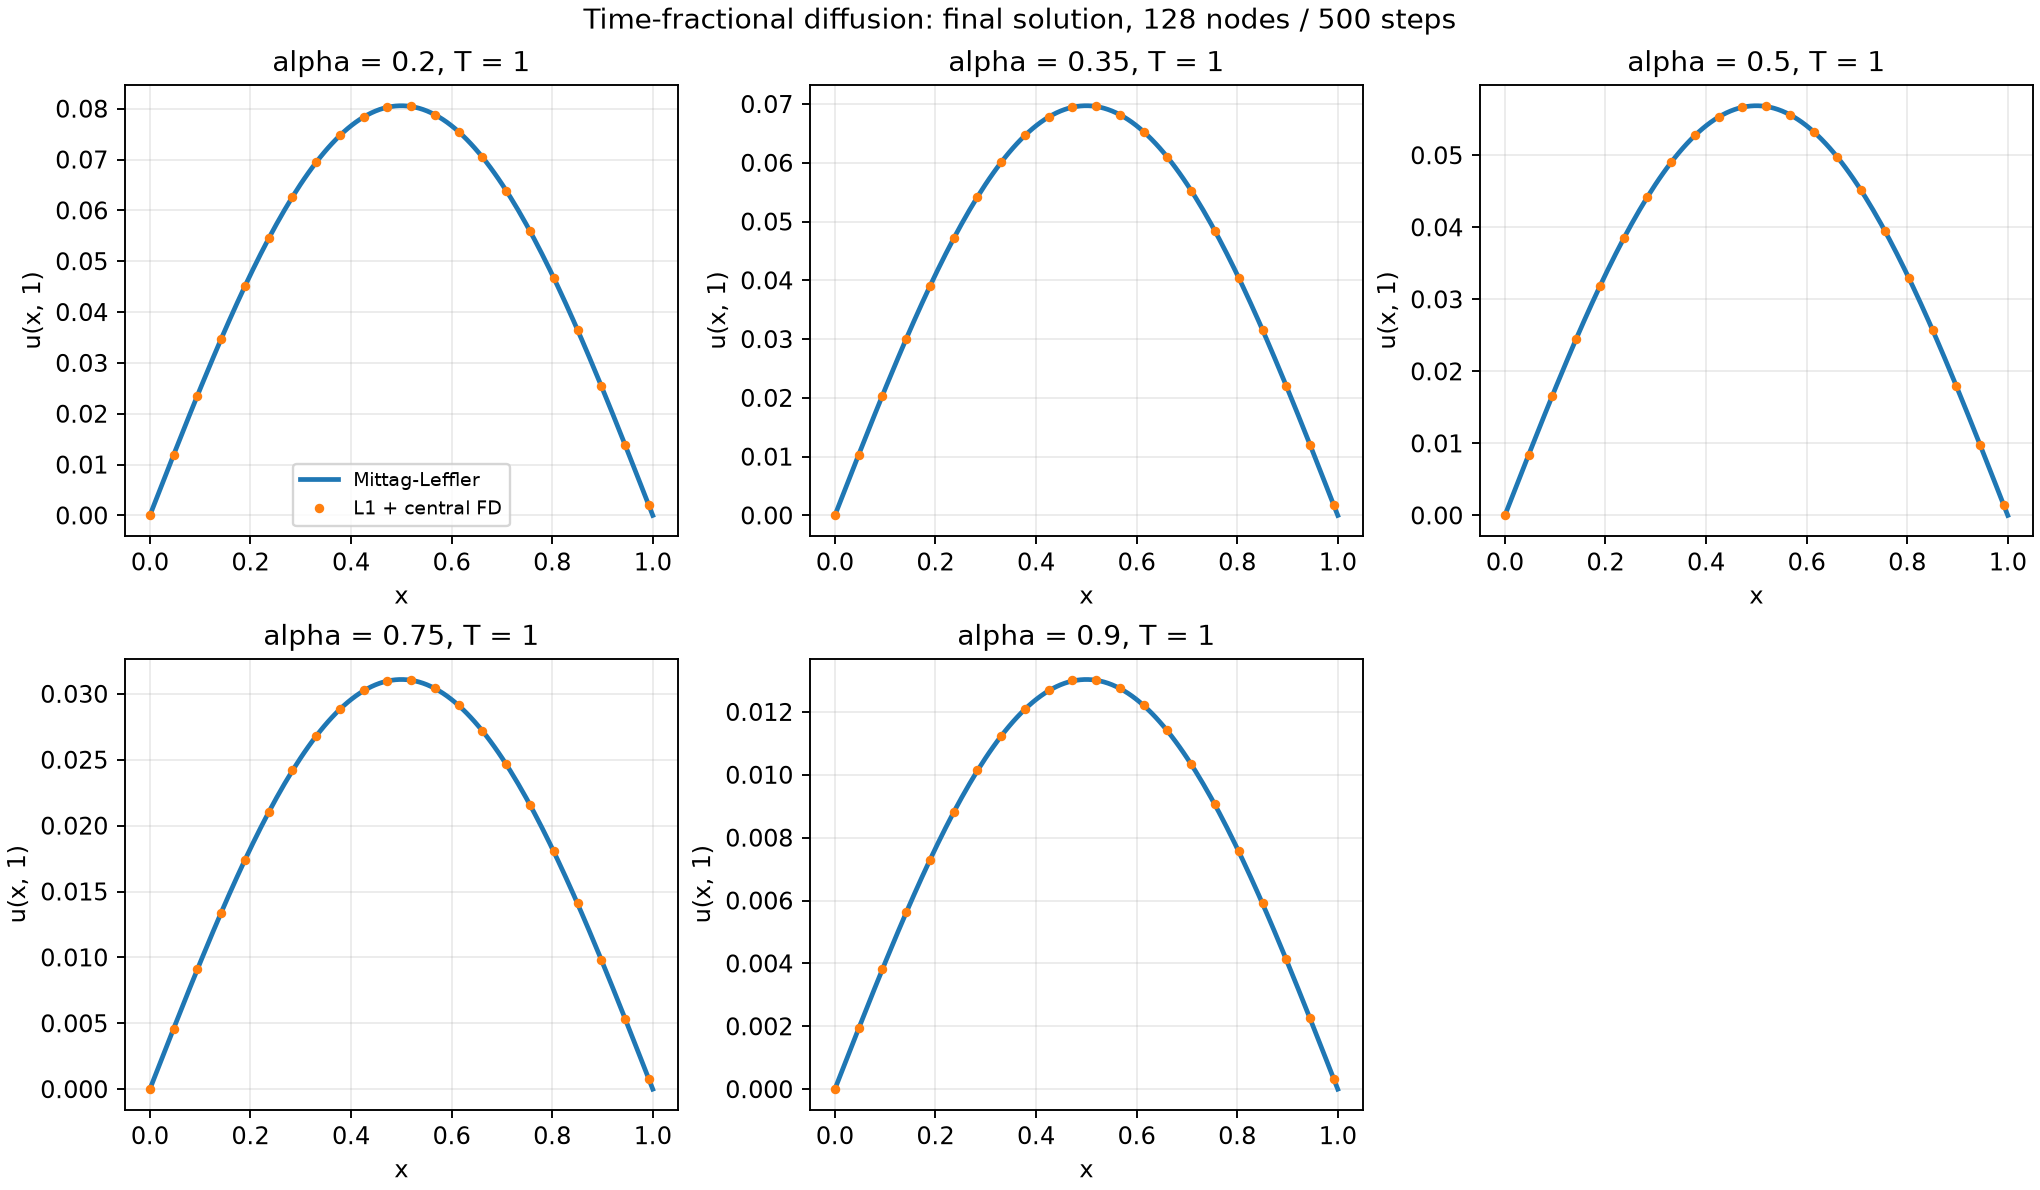

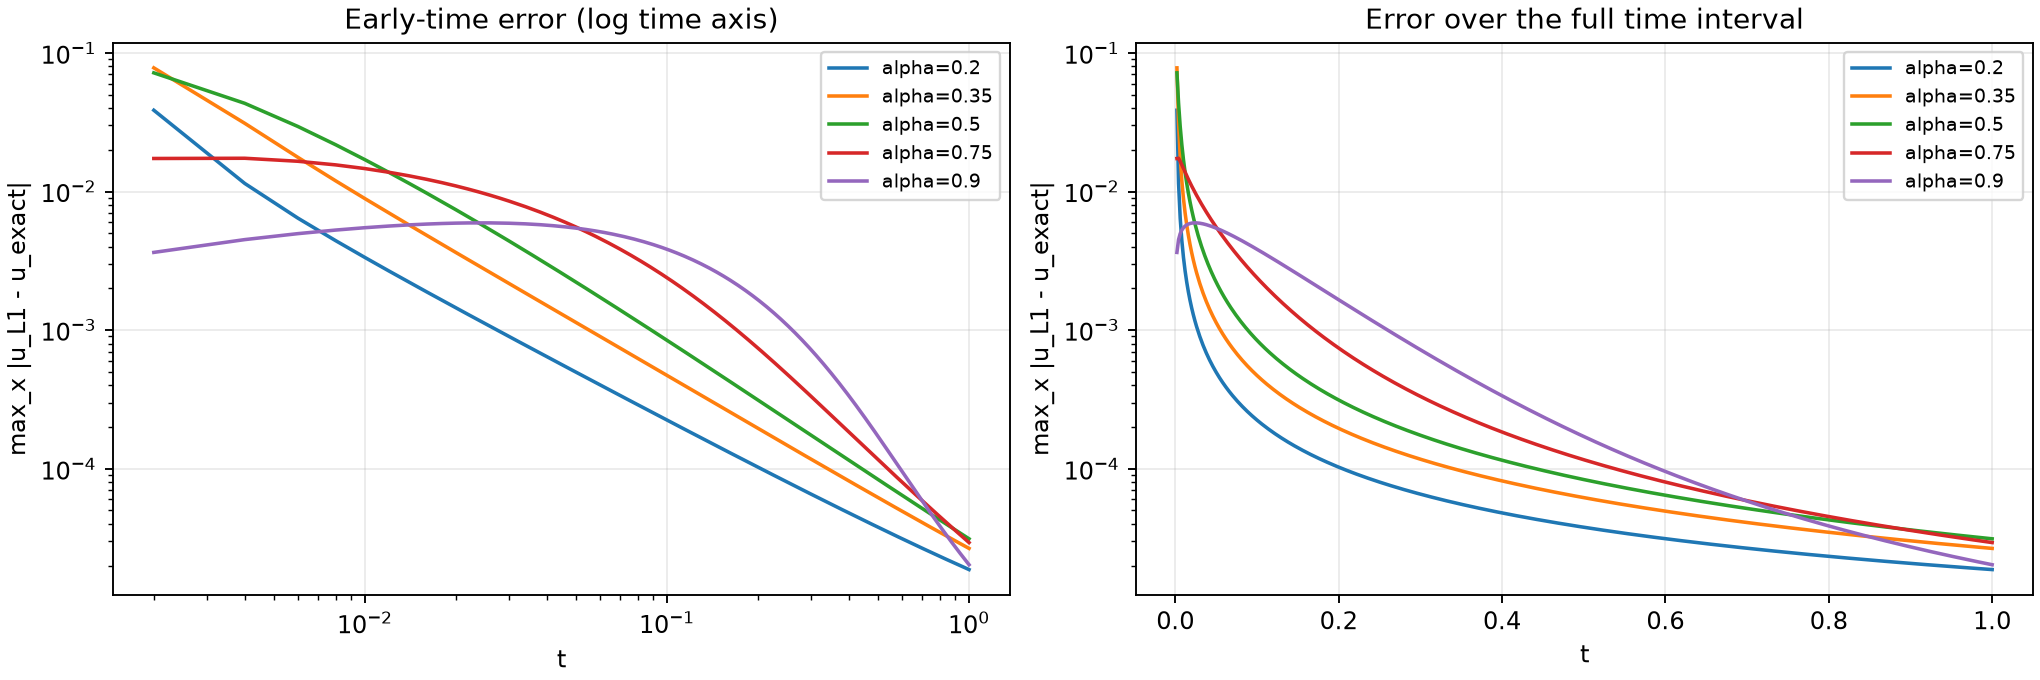

In [3]:
display(Image(filename=str(ROOT / 'results' / 'solution_comparison.png')))
display(Image(filename=str(ROOT / 'results' / 'error_vs_time.png')))

## Сходимость

Временную ошибку отделяем от пространственной: сравниваем L1 с точным временным решением пространственно дискретной системы, используя дискретное собственное значение. Для пространственной ошибки сравниваем точное временное распространение дискретной и непрерывной моделей. Это позволяет избежать маскировки временной ошибки пространственной. Проверки проводятся при T=1; порядок для гладких решений не переносим автоматически на ошибку у t=0.

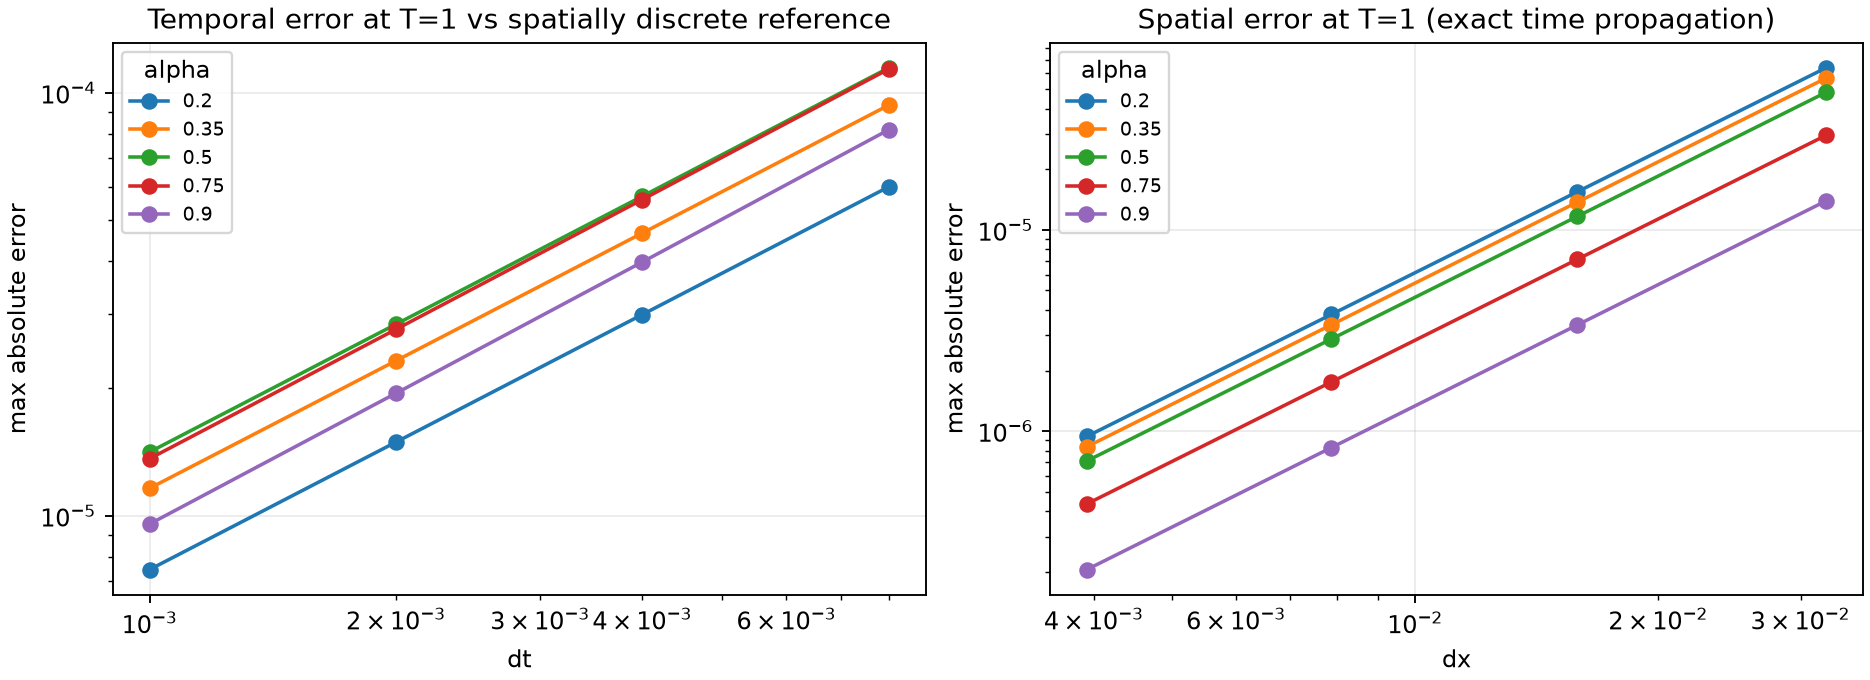

In [4]:
display(Image(filename=str(ROOT / 'results' / 'convergence.png')))

## Датасет

32 синусные моды с коэффициентами Normal(0,1)/sqrt(k), нормировка max|u0|=1. Seed: 20261016.

1000 обучающих примеров, 100 обычных тестовых, по 50 при alpha=0.35 и 0.75. Для каждой траектории сохранены t=0.01, 0.1, 0.5, 1. Траектория целиком принадлежит одному split. Метки получены L1 и центральными разностями; нормировка выхода вычислена только по train.


In [5]:
with np.load(ROOT / "data" / "dataset.npz", allow_pickle=False) as d:
    u0, alpha, uT, split, x, u, t = [d[key] for key in ["u0", "alpha", "uT", "split", "x", "u", "t"]]
    metadata = json.loads(d["metadata"].item())
    normalized = (u - d["output_mean"]) / d["output_scale"]
train = split == "train"
test = ~train
print("u0:", u0.shape, "u:", u.shape, "t:", t)
print("Splits:", dict(zip(*np.unique(split, return_counts=True))))
print("Normalized train mean:", normalized[train].mean(axis=(0, 2)))
print("Normalized train std:", normalized[train].std(axis=(0, 2)))
report = json.loads((ROOT / "results" / "dataset_report.json").read_text(encoding="utf-8"))
print("First-mode energy fractions:", report["first_mode_energy_fraction"])
print("Maximum relative L2 by time:", report["maximum_relative_l2_by_time"])


u0: (1200, 128) u: (1200, 4, 128) t: [0.01 0.1  0.5  1.  ]
Splits: {np.str_('test_alpha_035'): np.int64(50), np.str_('test_alpha_075'): np.int64(50), np.str_('test_random'): np.int64(100), np.str_('train'): np.int64(1000)}
Normalized train mean: [-5.57887070e-18 -2.45775622e-17  1.99562589e-17 -1.71321290e-17]
Normalized train std: [1. 1. 1. 1.]
First-mode energy fractions: [0.8807827819537177, 0.9702126744465495, 0.9597746094353266, 0.9581194283297725]
Maximum relative L2 by time: [0.0025548329268094716, 0.0022911113563097965, 0.0026562715763913704, 0.0022490403441002794]


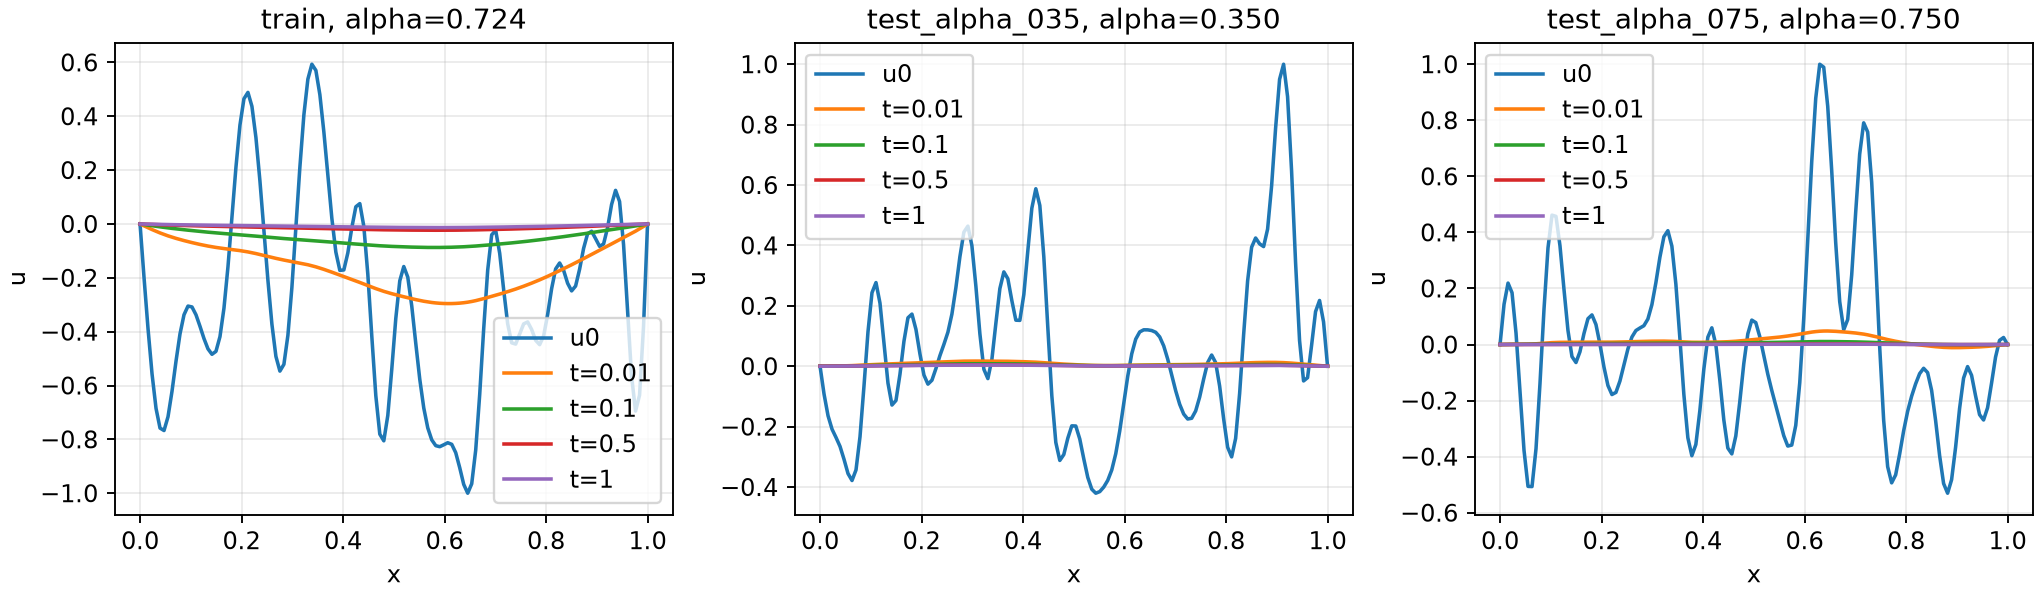

In [6]:
display(Image(filename=str(ROOT / 'results' / 'dataset_examples.png')))

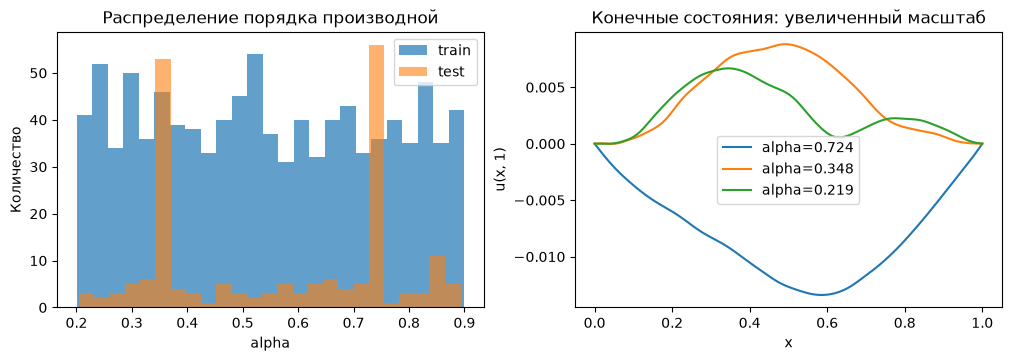

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout='constrained')
axes[0].hist(alpha[train], bins=25, label='train', alpha=.7)
axes[0].hist(alpha[test], bins=25, label='test', alpha=.6)
axes[0].set(xlabel='alpha', ylabel='Количество', title='Распределение порядка производной')
axes[0].legend()
for i in [0, 1, 2]:
    axes[1].plot(x, uT[i], label=f'alpha={alpha[i]:.3f}')
axes[1].set(xlabel='x', ylabel='u(x, 1)', title='Конечные состояния: увеличенный масштаб')
axes[1].legend()
plt.show()

## Границы результата

Датасет содержит 32 моды и четыре момента времени, тестовые начальные условия имеют то же распределение. Экстраполяция по alpha не проверяется. Каждый момент рассчитан на своей равномерной сетке из 500 шагов. Нормировка по времени не устраняет зависимость амплитуды от alpha. Обучение FNO и отдельные эксперименты с временной сеткой приведены ниже.


## FNO с alpha и временем на входе

900 начальных условий используются для обучения, 100 — для выбора checkpoint по validation; три тестовые группы оцениваются после выбора. Нормировка и одномодовый базовый метод обучены только на fitting IDs. Запуск обучения: `python -m src.train_fno`. Этот ноутбук загружает сохранённые результаты и не запускает обучение повторно.


Best epoch: 295
test_random
  t=0.01: FNO mean rel L2=1.671%, baseline=44.811%
  t=0.1: FNO mean rel L2=1.811%, baseline=33.380%
  t=0.5: FNO mean rel L2=1.171%, baseline=34.582%
  t=1: FNO mean rel L2=1.252%, baseline=35.261%
test_alpha_035
  t=0.01: FNO mean rel L2=1.087%, baseline=37.815%
  t=0.1: FNO mean rel L2=1.315%, baseline=35.481%
  t=0.5: FNO mean rel L2=0.794%, baseline=34.692%
  t=1: FNO mean rel L2=0.804%, baseline=34.473%
test_alpha_075
  t=0.01: FNO mean rel L2=1.756%, baseline=53.400%
  t=0.1: FNO mean rel L2=2.071%, baseline=35.467%
  t=0.5: FNO mean rel L2=1.458%, baseline=37.950%
  t=1: FNO mean rel L2=1.471%, baseline=39.109%


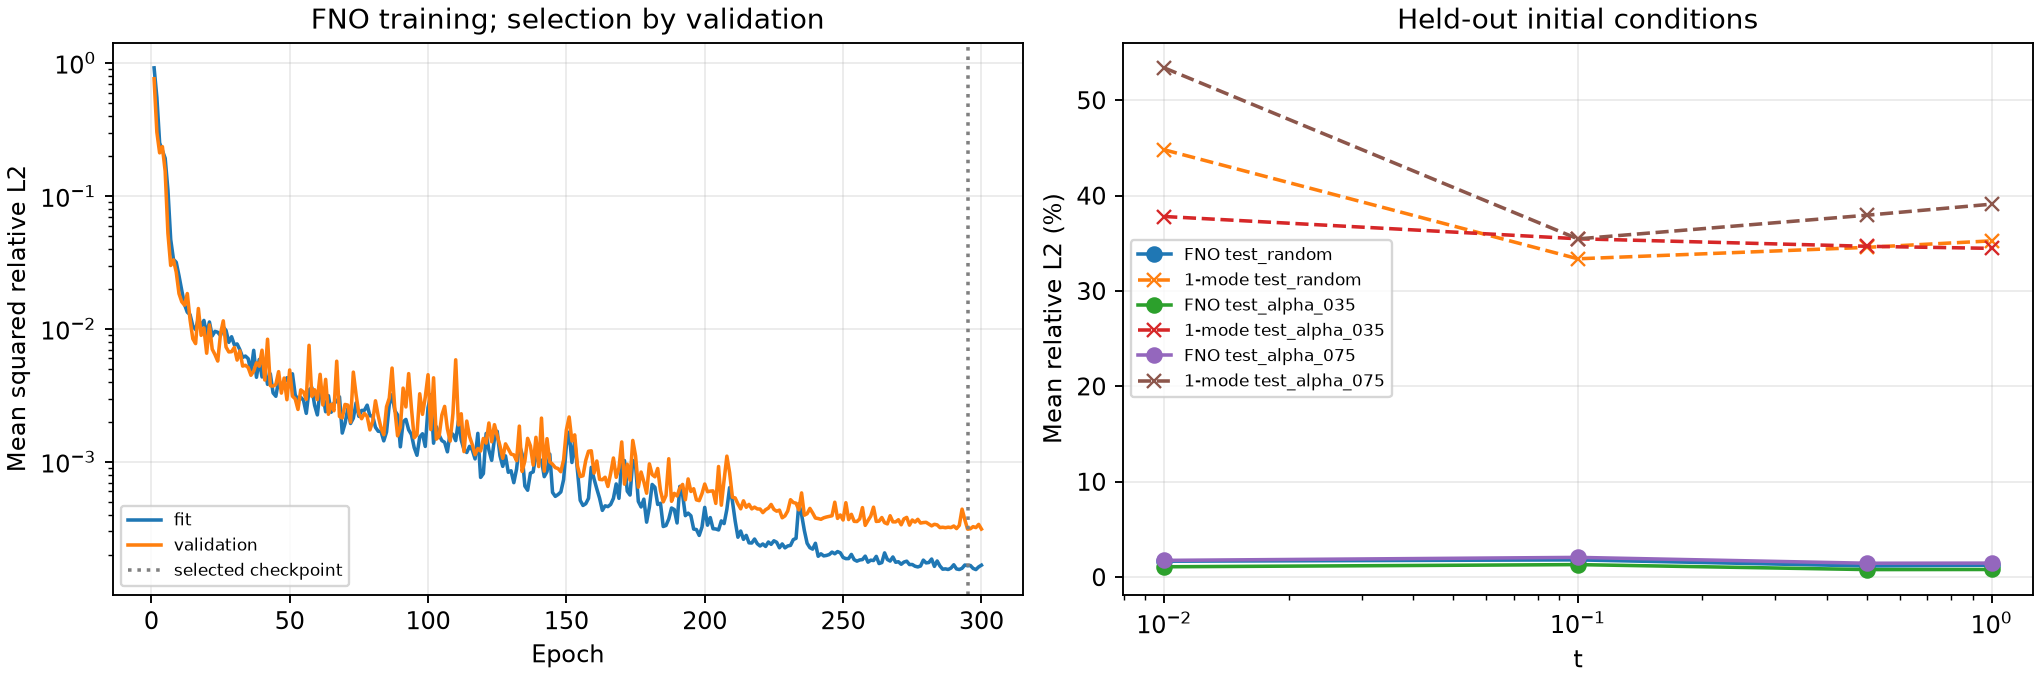

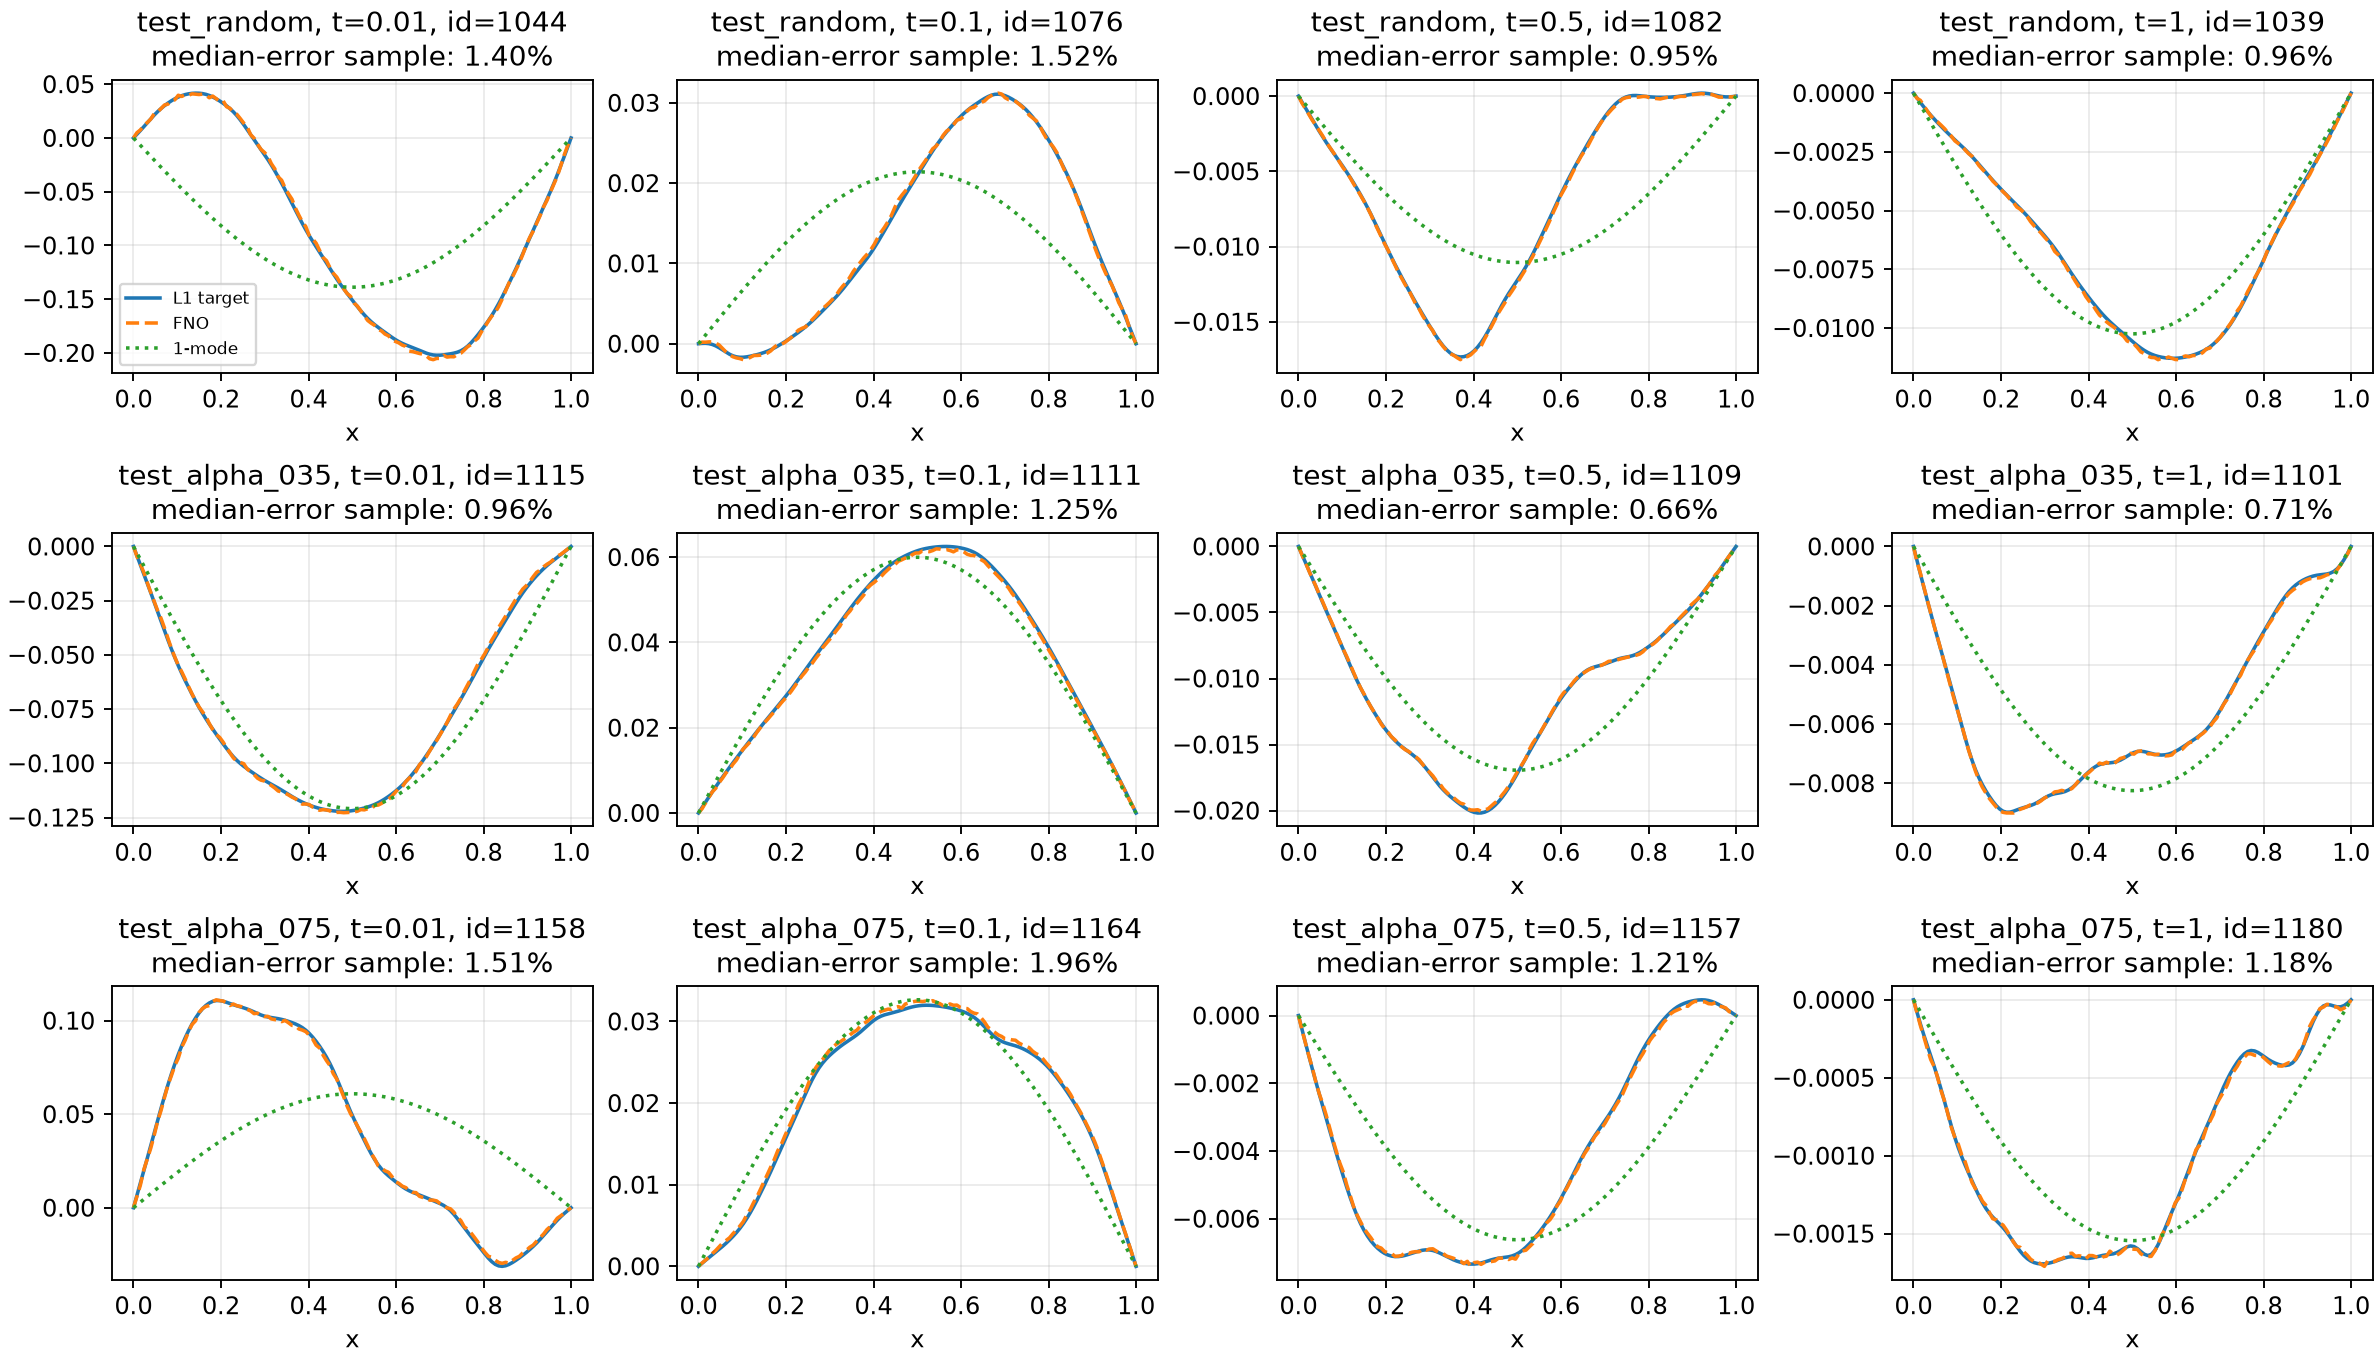

In [8]:
fno = json.loads((ROOT / "results" / "fno" / "metrics.json").read_text(encoding="utf-8"))
print("Best epoch:", fno["best_epoch"])
for group in ["test_random", "test_alpha_035", "test_alpha_075"]:
    print(group)
    for t, metrics in fno["metrics"][group].items():
        baseline = fno["first_mode_baseline_metrics"][group][t]
        print(f"  t={t}: FNO mean rel L2={metrics['mean_relative_l2']:.3%}, baseline={baseline['mean_relative_l2']:.3%}")
display(Image(filename=str(ROOT / "results" / "fno" / "training_metrics.png")))
display(Image(filename=str(ROOT / "results" / "fno" / "prediction_examples.png")))


## Сгущённая сетка и ускоренная история SOE

Эксперименты выполняются отдельно от генерации датасета: `python -m src.benchmark_solvers`. Эталон исключает пространственную ошибку. SOE сравнивается с полной L1 на той же сетке, включая подготовку ядра при оценке ускорения.


uniform 500 speedup: 0.674 SOE vs L1: 1.587618925213974e-11
uniform 2000 speedup: 1.168 SOE vs L1: 1.587551617943106e-11
uniform 10000 speedup: 3.258 SOE vs L1: 1.5875939451959198e-11
graded 500 speedup: 0.577 SOE vs L1: 1.587091569277277e-11
graded 2000 speedup: 1.171 SOE vs L1: 1.5872893277535383e-11
graded 10000 speedup: 2.736 SOE vs L1: 1.5873843906000218e-11


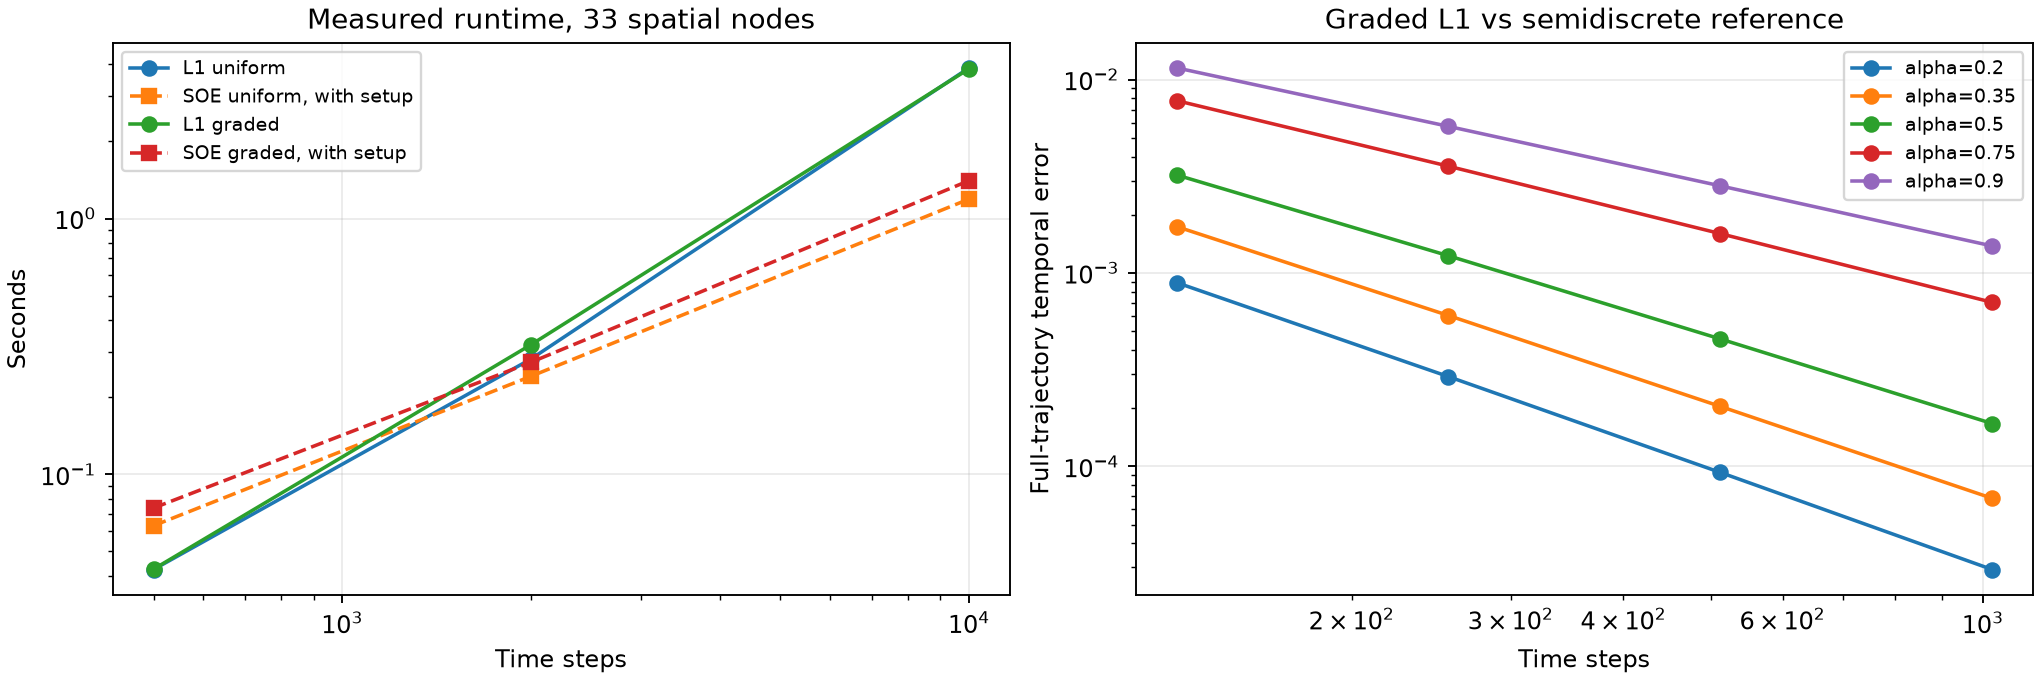

In [9]:
benchmark = json.loads((ROOT / "results" / "solver_benchmark.json").read_text(encoding="utf-8"))
for row in benchmark["runtime"]:
    print(row["mesh"], row["n_steps"], "speedup:", round(row["speedup_including_setup"], 3), "SOE vs L1:", row["maximum_soe_vs_full_l1"])
display(Image(filename=str(ROOT / "results" / "solver_benchmark.png")))
